# Task 4 — Historical Simulation VaR & Expected Shortfall
### QFI Internship · Market Risk Project · Phase 4
**Prepared by:** Arham Shah

---

**Objective.** Measure the downside risk of the Task 3 portfolio without assuming any distribution: the portfolio's own history defines what a bad day looks like. This sets the benchmark that every later model must beat.

**What this notebook delivers**
- Rolling one-day-ahead **HS VaR and ES** for 3 windows × 3 confidence levels (9 models), with an engine checked against a brute-force loop
- Evidence for **return-based scaling** over raw dollar P&L, in a portfolio that grew 4.5×
- The latest **risk grid**, an FRTB-style **ES 97.5%** view and a tail-loss profile
- The **ghost effect** shown on a real event in this portfolio
- A backtest preview: Kupiec test, a **Basel traffic light** over time, and the capital multiplier
- A uniform export (`HS_VaR.csv`) and the shared `VaR_Model_Summary.csv`

> **Pipeline:** Task 1 Data → Task 2 Cleaning → Task 3 Portfolio → **Task 4 HS VaR** → Task 5 EWMA-FHS → Task 6 GARCH-FHS → Task 7 → → Task 8 Backtesting → Task 9 Comparison

> **How to run:** Colab → *Runtime → Run all*. Running it after Task 3 in the same session means it uses `Portfolio_Construction.csv`. Otherwise it rebuilds that portfolio with the same Task 3 engine, so the numbers match.

## 1. Concepts in brief
**Value-at-Risk (VaR).** VaR at confidence *c* is the loss that should only be exceeded on (1 − c) of days. A 99% one-day VaR of $180k means we expect to lose more than $180k on about 1 day in 100, or roughly 2–3 days a year.

$$\text{VaR}_c = -Q_{1-c}(R)\qquad\text{ES}_c = -\mathbb E[R\mid R\le Q_{1-c}(R)]$$

**Expected Shortfall (ES).** ES is the *average* loss on the days that breach VaR, so it answers "how bad is it when it goes wrong?". ES is *coherent* (it rewards diversification), which is why Basel's FRTB replaced 99% VaR with **97.5% ES**.

**Historical Simulation (HS).** Treat each of the last *W* daily returns as an equally likely scenario for tomorrow and read off the percentile.

| Strength | Weakness |
|---|---|
| No normality assumption; fat tails and skew come straight from the data | Reacts slowly: risk only rises *after* losses enter the window |
| Simple and easy to audit | **Ghost effect**: a crash keeps VaR high for exactly *W* days, then drops off a cliff |
| No covariance matrix needed | Can never forecast a loss larger than the worst day in the window |

**Window choice** trades responsiveness against stability. 250 days is reactive but noisy, since only about 2.5 observations lie beyond the 99% threshold. 750 days is stable but remembers old crises. Tasks 5 and 6 fix the slow reaction with volatility scaling.

## Conventions used in every VaR task (4 → 9)
| Convention | Choice | Why |
|---|---|---|
| Horizon | 1 trading day | Standard for daily risk limits and backtesting |
| Timing | VaR for day *t* uses data up to *t − 1* only | No look-ahead, so it is a genuine forecast that can be backtested |
| Sign | VaR and ES are **positive losses** | Easier to read: "we could lose $X" |
| Units | Model on **returns**, then convert to dollars with the **start-of-day value** | The portfolio grew from $1M to $4.5M, so old dollar P&L understates today's risk |
| Exception | Return < −VaR (equivalently P&L < −VaR$) | Basel definition |
| Headline | 99% confidence, 250-day window | Basel internal-models standard |
| Export | `<MODEL>_VaR.csv` with identical column patterns | Task 8 and Task 9 can read every model the same way |

In [1]:
# ---- Setup ---------------------------------------------------------------
import os, json, time, warnings
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from numpy.lib.stride_tricks import sliding_window_view
from scipy import stats
from scipy.signal import lfilter
from IPython.display import display, Markdown
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
plt.rcParams.update({
    'figure.figsize': (13, 5), 'figure.dpi': 110,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.3, 'axes.titleweight': 'bold',
    'axes.titlesize': 13, 'legend.frameon': False,
})
AUTHOR = 'Arham Shah'
print(f'Environment ready | pandas {pd.__version__} | numpy {np.__version__} | run by {AUTHOR}')

Environment ready | pandas 2.2.2 | numpy 1.26.4 | run by Arham Shah


In [2]:
# ---- Project configuration (identical across Tasks 1-10) ------------------
UNIVERSE = {'AAPL': 'Information Technology', 'MSFT': 'Information Technology',
            'NVDA': 'Information Technology', 'GOOGL': 'Communication Services',
            'META': 'Communication Services', 'AMZN': 'Consumer Discretionary',
            'TSLA': 'Consumer Discretionary', 'JPM': 'Financials',
            'XOM': 'Energy', 'UNH': 'Health Care'}
TICKERS, BENCHMARK = list(UNIVERSE), '^GSPC'
START_DATE, END_DATE = '2020-07-24', '2026-07-25'
INITIAL_VALUE, REBALANCE, COST_BPS = 1_000_000, 'M', 5        # Task 3 portfolio
TRADING_DAYS = 252
PORTFOLIO_FILE = 'Portfolio_Construction.csv'                  # Task 3 output

# ---- Risk-model settings shared by every VaR model (Tasks 4-9) ----
WINDOWS     = (250, 500, 750)          # ~1, 2, 3 years of history
CONFIDENCES = (0.95, 0.99, 0.995)
HEADLINE_W, HEADLINE_CL = 250, 0.99    # Basel-style headline: 99%, 1-year window
EWMA_LAMBDA = 0.94                     # RiskMetrics daily decay (same as Task 2)
CCY = '$'
SUMMARY_FILE = 'VaR_Model_Summary.csv' # one row per model x window x confidence

COLORS = {'HS': '#E08A2E', 'EWMA': '#6A2C91', 'GARCH': '#1F7A8C',
          250: '#E08A2E', 500: '#C0392B', 750: '#5B2C6F',
          'loss': '#B03A2E', 'gain': '#2E7D68', 'muted': '#8C99A6', 'ink': '#1B2A41'}

def tag(c):   return f'{100*c:g}'.replace('.', 'p')          # 0.995 -> '99p5'
def pct(x, dp=2):   return 'n/a' if not np.isfinite(x) else f'{100*x:.{dp}f}%'
def money(x, dp=0): return 'n/a' if not np.isfinite(x) else f'{CCY}{x:,.{dp}f}'
usd_fmt = mtick.FuncFormatter(lambda x, _: f'{CCY}{x/1e3:,.0f}k')
print(f'Windows {WINDOWS} | confidences {CONFIDENCES} | headline {HEADLINE_CL:.0%} / {HEADLINE_W}d')

Windows (250, 500, 750) | confidences (0.95, 0.99, 0.995) | headline 99% / 250d


## 2. Load the Task 3 portfolio

In [3]:
# ---- Load the Task 3 portfolio (or rebuild it identically if missing) -----
def rebuild_portfolio():
    """Re-creates Task 3's monthly-rebalanced equal-weight portfolio from Yahoo data."""
    try:
        import yfinance as yf
    except ImportError:
        %pip install -q yfinance
        import yfinance as yf
    def adj(symbols):
        px = yf.download(symbols, start=START_DATE, end=END_DATE, auto_adjust=False, progress=False)['Adj Close']
        return px.to_frame(symbols[0]) if isinstance(px, pd.Series) else px
    bench = adj([BENCHMARK]).iloc[:, 0].dropna()
    px = adj(TICKERS)[TICKERS].reindex(bench.index).ffill(limit=3).dropna()
    rets = px.pct_change().iloc[1:]
    w, c = np.repeat(1 / len(TICKERS), len(TICKERS)), COST_BPS / 1e4
    s = pd.Series(rets.index, index=rets.index)
    rb = set(s.groupby(rets.index.to_period(REBALANCE)).max()) - {rets.index[-1]}
    h = INITIAL_VALUE / (1 + c) * w
    vals = [h.sum()]
    for d, r in zip(rets.index, rets.values):
        h = h * (1 + r); V = h.sum()
        if d in rb:
            V -= np.abs(V * w - h).sum() * c; h = V * w
        vals.append(V)
    v = pd.Series(vals, index=px.index)
    out = pd.DataFrame({'Return': v.pct_change(), 'Value': v, 'PnL': v.diff()})
    out.iloc[0] = [v.iloc[0] / INITIAL_VALUE - 1, v.iloc[0], v.iloc[0] - INITIAL_VALUE]
    out['Benchmark_Return'] = bench.reindex(out.index).pct_change()
    out.index.name = 'Date'
    out.to_csv(PORTFOLIO_FILE)
    return out

if os.path.exists(PORTFOLIO_FILE):
    raw = pd.read_csv(PORTFOLIO_FILE, index_col=0, parse_dates=True)
    SOURCE = f'{PORTFOLIO_FILE} (Task 3 output)'
else:
    raw = rebuild_portfolio()
    SOURCE = 'rebuilt from Yahoo Finance with the Task 3 engine (file not found)'

pf = raw[['Return', 'PnL', 'Value']].astype(float).copy()
pf['Start_Value'] = pf['Value'].shift(1)            # capital at risk at the start of each day
pf = pf.iloc[1:]                                    # drop day 0 (purchase day, not a market move)
assert np.allclose(pf['PnL'], pf['Return'] * pf['Start_Value']), 'P&L / return mismatch'
assert pf.isna().sum().sum() == 0, 'unexpected gaps in the portfolio series'

returns, pnl, start_value = pf['Return'], pf['PnL'], pf['Start_Value']
NAV = float(pf['Value'].iloc[-1])
print(f'Source : {SOURCE}')
print(f'Sample : {returns.index[0]:%d %b %Y} -> {returns.index[-1]:%d %b %Y} ({len(returns):,} daily returns)')
print(f'NAV    : {money(NAV)} | realised vol {pct(returns.std() * np.sqrt(TRADING_DAYS))} p.a.')

Source : Portfolio_Construction.csv (Task 3 output)
Sample : 27 Jul 2020 -> 24 Jul 2026 (1,506 daily returns)
NAV    : $4,520,228 | realised vol 22.97% p.a.


In [4]:
jb = stats.jarque_bera(returns)
profile = pd.Series({
    'Daily returns': f'{len(returns):,}',
    'Annualised volatility': pct(returns.std() * np.sqrt(TRADING_DAYS)),
    'Skewness': f'{returns.skew():.2f}',
    'Excess kurtosis': f'{returns.kurt():.2f}  (Normal = 0)',
    'Jarque-Bera p-value': f'{jb.pvalue:.1e}  -> normality rejected' if jb.pvalue < 0.05 else f'{jb.pvalue:.3f}',
    'Worst day': f'{pct(returns.min())} on {returns.idxmin():%d %b %Y}  ({money(pnl[returns.idxmin()])})',
    'Largest $ loss': f'{money(pnl.min())} on {pnl.idxmin():%d %b %Y}',
    'Best day': f'{pct(returns.max())} on {returns.idxmax():%d %b %Y}',
    'Days with loss > 3%': f'{(returns < -0.03).sum()}  (Normal would predict {stats.norm.cdf(-0.03, returns.mean(), returns.std()) * len(returns):.1f})',
}, name='Value').to_frame()
profile

,Value
Daily returns,"1,506"
Annualised volatility,22.97%
Skewness,0.06
Excess kurtosis,4.44 (Normal = 0)
Jarque-Bera p-value,2.6e-267 -> normality rejected
Worst day,"-5.87% on 04 Apr 2025 ($-182,173)"
Largest $ loss,"$-183,962 on 03 Apr 2025"
Best day,11.88% on 09 Apr 2025
Days with loss > 3%,33 (Normal would predict 23.8)


## 3. The risk engine
The engine computes every rolling window in one vectorised step using `sliding_window_view`, a zero-copy matrix of all windows. This is much faster than `rolling().apply()`. **Timing:** the window for day *t* ends at *t − 1*. Before trusting the engine, we check it against a plain Python loop.

In [5]:
# ---- Shared risk toolkit (identical in Tasks 4-6) -------------------------
def var_es(x, c):
    """Empirical VaR and ES of a return sample, as POSITIVE losses."""
    x = np.asarray(x, float); q = np.quantile(x, 1 - c)
    return -q, -x[x <= q].mean()

def rolling_hs(r, window, c):
    """One-day-ahead rolling HS VaR/ES. The value on day t uses r[t-W .. t-1] only."""
    v = np.asarray(r, float)
    out = pd.DataFrame(np.nan, index=r.index, columns=['VaR', 'ES'])
    if len(v) <= window:
        return out
    sw = sliding_window_view(v[:-1], window)          # row i = v[i : i+W] -> forecast for day i+W
    q = np.quantile(sw, 1 - c, axis=1)
    m = sw <= q[:, None]
    out.iloc[window:, 0] = -q
    out.iloc[window:, 1] = -(sw * m).sum(1) / m.sum(1)
    return out

def rolling_fhs(r, sigma, window, c):
    """Filtered HS (Hull-White): replay standardised shocks z = r/sigma at today's sigma."""
    return rolling_hs(r / sigma, window, c).mul(sigma, axis=0)

def kupiec(x, n, c):
    """Kupiec proportion-of-failures LR test -> (LR, p-value)."""
    p = 1 - c
    if n == 0: return np.nan, np.nan
    ph = x / n
    ll0 = (n - x) * np.log(1 - p) + x * np.log(p)
    ll1 = (n - x) * np.log(1 - ph) + (x * np.log(ph) if x > 0 else 0) if ph < 1 else 0
    lr = -2 * (ll0 - ll1)
    return lr, 1 - stats.chi2.cdf(lr, 1)

def basel_zone(x250):
    return 'GREEN' if x250 <= 4 else ('YELLOW' if x250 <= 9 else 'RED')
BASEL_MULT = {**{k: 3.0 for k in range(5)}, 5: 3.4, 6: 3.5, 7: 3.65, 8: 3.75, 9: 3.85}

def ljung_box(x, lags=10):
    x = np.asarray(x, float); x = x - x.mean(); n = len(x); d = x @ x
    rho = np.array([(x[k:] @ x[:-k]) / d for k in range(1, lags + 1)])
    q = n * (n + 2) * np.sum(rho**2 / (n - np.arange(1, lags + 1)))
    return q, 1 - stats.chi2.cdf(q, lags)

def backtest_table(model, panel, r=None, dates=None):
    """Exception counts + Kupiec + Basel zone for every (window, confidence)."""
    r = returns if r is None else r
    rows = []
    for (w, c), df in panel.items():
        f = df['VaR'].dropna()
        if dates is not None: f = f.loc[f.index.intersection(dates)]
        hit = r.reindex(f.index) < -f
        n, x = len(f), int(hit.sum())
        lr, p = kupiec(x, n, c)
        x250 = int(hit.iloc[-250:].sum())
        rows.append({'Model': model, 'Window': w, 'Confidence': c,
                     'Start': f.index[0].date(), 'Days': n, 'Exceptions': x,
                     'Expected': n * (1 - c), 'Rate': x / n, 'Kupiec p': p,
                     'Kupiec': 'PASS' if p > 0.05 else 'REJECT',
                     'Last 250d exc.': x250,
                     'Basel zone': basel_zone(x250) if c == 0.99 else '-',
                     'Avg VaR %': f.mean(), 'Avg ES %': df['ES'].reindex(f.index).mean(),
                     'VaR churn %': f.diff().abs().mean()})
    return pd.DataFrame(rows)

def style_bt(t):
    zc = {'GREEN': '#2E7D68', 'YELLOW': '#C78B00', 'RED': '#B03A2E', 'PASS': '#2E7D68', 'REJECT': '#B03A2E'}
    return (t.style.format({'Confidence': '{:.1%}', 'Expected': '{:.1f}', 'Rate': '{:.2%}', 'Kupiec p': '{:.3f}',
                            'Avg VaR %': '{:.2%}', 'Avg ES %': '{:.2%}', 'VaR churn %': '{:.3%}'})
             .map(lambda v: f'color:{zc[v]};font-weight:bold' if v in zc else '', subset=['Kupiec', 'Basel zone'])
             .hide(axis='index'))

def export_model(model, panel, fname):
    """Uniform export schema consumed by Task 8 (backtesting) and Task 9 (comparison)."""
    out = pf[['Return', 'PnL', 'Start_Value']].copy()
    for (w, c), df in panel.items():
        k = f'{model}_{{}}_{w}d_{tag(c)}'
        out[k.format('VaR') + '_Ret'] = df['VaR']
        out[k.format('ES') + '_Ret'] = df['ES']
        out[k.format('VaR')] = df['VaR'] * pf['Start_Value']
        out[k.format('ES')] = df['ES'] * pf['Start_Value']
        out[k.format('Breach')] = (pf['Return'] < -df['VaR']).astype(float).where(df['VaR'].notna())
    out.to_csv(fname, date_format='%Y-%m-%d')
    dd = pd.DataFrame([
        ('Return', 'decimal', 'Realised daily portfolio return (Task 3)'),
        ('PnL', CCY, 'Realised daily P&L = Return x Start_Value'),
        ('Start_Value', CCY, 'Portfolio value at the start of the day (capital at risk)'),
        (f'{model}_VaR_<W>d_<CL>_Ret', 'positive decimal', 'One-day-ahead VaR forecast as a return (uses data to t-1 only)'),
        (f'{model}_ES_<W>d_<CL>_Ret', 'positive decimal', 'One-day-ahead Expected Shortfall as a return'),
        (f'{model}_VaR_<W>d_<CL>', CCY, 'VaR in dollars = VaR_Ret x Start_Value'),
        (f'{model}_ES_<W>d_<CL>', CCY, 'ES in dollars = ES_Ret x Start_Value'),
        (f'{model}_Breach_<W>d_<CL>', '1/0/NaN', '1 if Return < -VaR (an exception); NaN before the first forecast'),
    ], columns=['Column', 'Unit', 'Definition'])
    dd.to_csv(fname.replace('.csv', '_Dictionary.csv'), index=False)
    print(f'Saved {fname} ({out.shape[0]:,} rows x {out.shape[1]} cols) + data dictionary')
    return out

def update_summary(bt, next_day):
    """Upsert this model's rows into the shared cross-model summary file."""
    rows = bt.copy()
    rows['Next-day VaR %'] = [next_day[(w, c)][0] for w, c in zip(rows['Window'], rows['Confidence'])]
    rows['Next-day ES %'] = [next_day[(w, c)][1] for w, c in zip(rows['Window'], rows['Confidence'])]
    rows['Next-day VaR $'] = rows['Next-day VaR %'] * NAV
    rows['Next-day ES $'] = rows['Next-day ES %'] * NAV
    rows['Updated'] = datetime.now().isoformat(timespec='seconds')
    if os.path.exists(SUMMARY_FILE):
        old = pd.read_csv(SUMMARY_FILE)
        rows = pd.concat([old[old['Model'] != rows['Model'].iloc[0]], rows], ignore_index=True)
    rows.to_csv(SUMMARY_FILE, index=False)
    print(f'{SUMMARY_FILE} now holds models: {sorted(rows["Model"].unique())}')

print('Risk toolkit loaded.')

Risk toolkit loaded.


In [6]:
# Validation: vectorised engine == brute-force loop (VaR and ES)
fast = rolling_hs(returns, 250, 0.99)
for t in [250, 600, 1000, len(returns) - 1]:
    v, e = var_es(returns.iloc[t - 250:t], 0.99)
    assert np.isclose(fast['VaR'].iloc[t], v) and np.isclose(fast['ES'].iloc[t], e)
assert fast['VaR'].iloc[:250].isna().all()            # no forecast until a full window exists
print('Engine validated: vectorised rolling VaR/ES matches the brute-force loop; no look-ahead.')

HS = {(w, c): rolling_hs(returns, w, c) for w in WINDOWS for c in CONFIDENCES}
print(f'Built {len(HS)} rolling HS models '
      f'(first forecasts: ' + ', '.join(f'{w}d from {HS[(w, 0.99)]["VaR"].first_valid_index():%b %Y}' for w in WINDOWS) + ')')

Engine validated: vectorised rolling VaR/ES matches the brute-force loop; no look-ahead.


Built 9 rolling HS models (first forecasts: 250d from Jul 2021, 500d from Jul 2022, 750d from Jul 2023)


## 4. Why we model returns, not raw dollar P&L
A common shortcut is to take percentiles of the dollar P&L history directly. That breaks for a growing portfolio. A −3% day in 2020 lost about $30k, but the same move today loses about $135k, so a dollar-based HS sees "small" historical losses and **understates risk**. Using returns × start-of-day value replays every historical move at today's size.

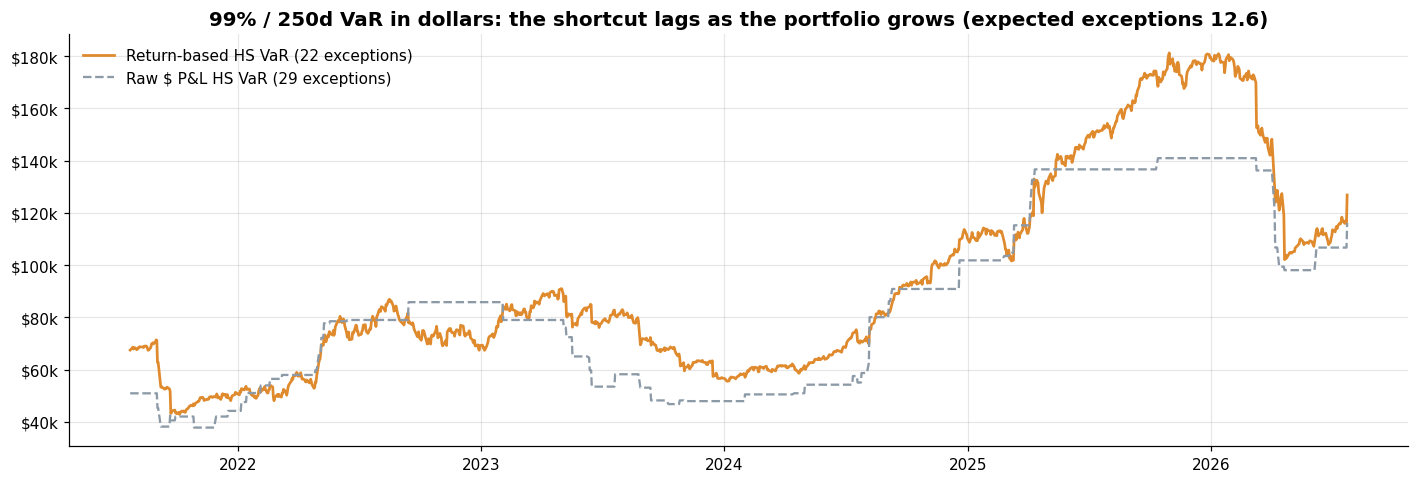

On average the P&L-based shortcut understates VaR by 12.4%.


In [7]:
w, c = HEADLINE_W, HEADLINE_CL
var_pnl = -pnl.rolling(w).quantile(1 - c).shift(1)                 # shortcut: $ P&L percentiles
var_ret = HS[(w, c)]['VaR'] * start_value                          # return-based, scaled to today's size
both = pd.DataFrame({'P&L-based': var_pnl, 'Return-based': var_ret}).dropna()
exc = {k: int((pnl.reindex(both.index) < -both[k]).sum()) for k in both}
exp_n = len(both) * (1 - c)

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(both['Return-based'], color=COLORS['HS'], lw=1.8, label=f'Return-based HS VaR ({exc["Return-based"]} exceptions)')
ax.plot(both['P&L-based'], color=COLORS['muted'], lw=1.5, ls='--', label=f'Raw $ P&L HS VaR ({exc["P&L-based"]} exceptions)')
ax.yaxis.set_major_formatter(usd_fmt); ax.legend(loc='upper left')
ax.set_title(f'{c:.0%} / {w}d VaR in dollars: the shortcut lags as the portfolio grows (expected exceptions {exp_n:.1f})')
plt.tight_layout(); plt.show()
gap = (both['Return-based'] / both['P&L-based'] - 1).mean()
print(f'On average the P&L-based shortcut understates VaR by {gap:.1%}.')

## 5. Today's risk grid (forecast for the next trading day)
The latest window of each length is used to forecast tomorrow, scaled to the current NAV. `Tail obs` counts how many historical days sit beyond the threshold. Fewer than about 5 means the estimate rests on a handful of days, so treat it with caution.

In [8]:
norm_ratio = lambda c: stats.norm.pdf(stats.norm.ppf(c)) / (1 - c) / stats.norm.ppf(c)
NEXT = {}
rows = []
for w in WINDOWS:
    x = returns.iloc[-w:]
    for c in CONFIDENCES:
        v, e = var_es(x, c); NEXT[(w, c)] = (v, e)
        rows.append({'Window': f'{w}d', 'Confidence': f'{c:.1%}', 'VaR %': v, 'ES %': e,
                     'VaR $': v * NAV, 'ES $': e * NAV, 'ES/VaR': e / v, 'Normal ES/VaR': norm_ratio(c),
                     'Tail obs': int((x <= -v).sum())})
grid = pd.DataFrame(rows)
grid.to_csv('HS_VaR_ES_Grid.csv', index=False)
(grid.style.format({'VaR %': '{:.2%}', 'ES %': '{:.2%}', 'VaR $': '${:,.0f}', 'ES $': '${:,.0f}',
                    'ES/VaR': '{:.2f}', 'Normal ES/VaR': '{:.2f}'})
     .background_gradient(subset=['VaR $', 'ES $'], cmap='Reds')
     .map(lambda v: 'color:#B03A2E;font-weight:bold' if isinstance(v, int) and v < 5 else '', subset=['Tail obs'])
     .hide(axis='index'))

Window,Confidence,VaR %,ES %,VaR $,ES $,ES/VaR,Normal ES/VaR,Tail obs
250d,95.0%,1.65%,2.38%,"$74,562","$107,635",1.44,1.25,13
250d,99.0%,2.81%,3.18%,"$126,797","$143,752",1.13,1.15,3
250d,99.5%,3.13%,3.27%,"$141,587","$147,824",1.04,1.12,2
500d,95.0%,2.11%,3.09%,"$95,210","$139,588",1.47,1.25,25
500d,99.0%,3.37%,4.70%,"$152,264","$212,286",1.39,1.15,5
500d,99.5%,4.17%,5.25%,"$188,628","$237,110",1.26,1.12,3
750d,95.0%,1.87%,2.82%,"$84,376","$127,257",1.51,1.25,38
750d,99.0%,3.24%,4.25%,"$146,470","$192,295",1.31,1.15,8
750d,99.5%,3.96%,4.95%,"$178,876","$223,768",1.25,1.12,4


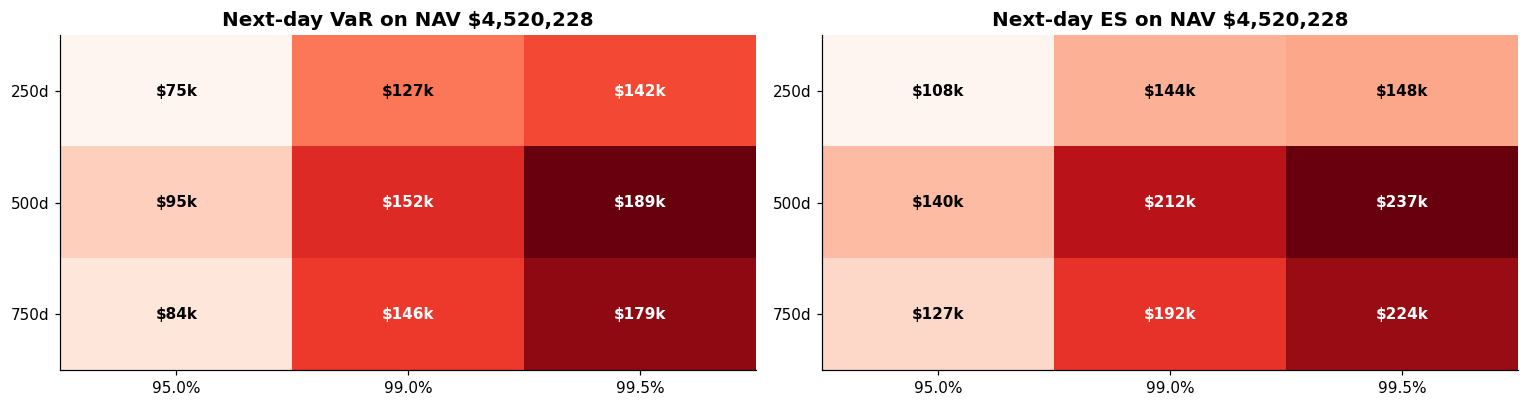

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
for ax, k in zip(axes, ['VaR $', 'ES $']):
    m = grid.pivot(index='Window', columns='Confidence', values=k).loc[[f'{w}d' for w in WINDOWS]]
    im = ax.imshow(m.values, cmap='Reds', aspect='auto')
    ax.set_xticks(range(m.shape[1]), m.columns); ax.set_yticks(range(m.shape[0]), m.index)
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            ax.text(j, i, f'${m.values[i, j]/1e3:,.0f}k', ha='center', va='center', fontweight='bold',
                    color='white' if m.values[i, j] > m.values.mean() else 'black')
    ax.grid(False); ax.set_title(f'Next-day {k[:-2]} on NAV {money(NAV)}')
plt.tight_layout(); plt.show()

## 6. The return distribution and its tail

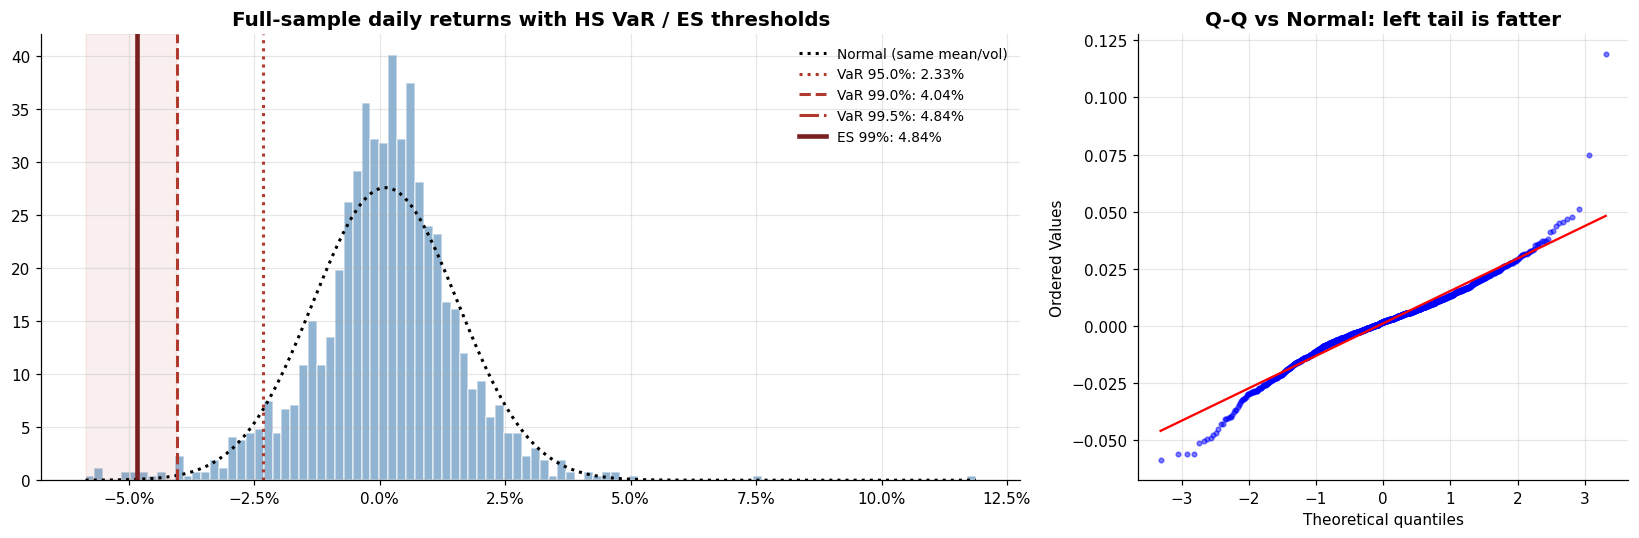

In [10]:
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={'width_ratios': [2, 1]})
ax.hist(returns, bins=100, density=True, color='steelblue', alpha=0.6, edgecolor='white')
g = np.linspace(returns.min(), returns.max(), 500)
ax.plot(g, stats.norm.pdf(g, returns.mean(), returns.std()), 'k:', lw=2, label='Normal (same mean/vol)')
for c, ls in zip(CONFIDENCES, [':', '--', '-.']):
    v, _ = var_es(returns, c)
    ax.axvline(-v, color=COLORS['loss'], ls=ls, lw=2, label=f'VaR {c:.1%}: {pct(v)}')
v99, e99 = var_es(returns, 0.99)
ax.axvline(-e99, color='#7A1F1F', lw=3, label=f'ES 99%: {pct(e99)}')
ax.axvspan(returns.min(), -v99, color=COLORS['loss'], alpha=0.08)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.legend(fontsize=9)
ax.set_title('Full-sample daily returns with HS VaR / ES thresholds')
stats.probplot(returns, dist='norm', plot=ax2)
ax2.get_lines()[0].set(markersize=3, alpha=0.5); ax2.set_title('Q-Q vs Normal: left tail is fatter')
plt.tight_layout(); plt.show()

In [11]:
worst = returns.nsmallest(10).to_frame('Return')
worst['P&L $'] = pnl.loc[worst.index]
worst['Loss at today\'s NAV $'] = -worst['Return'] * NAV
worst['S&P 500'] = raw['Benchmark_Return'].reindex(worst.index) if 'Benchmark_Return' in raw else np.nan
worst['Type'] = np.where(worst['S&P 500'] < -0.02, 'Market-wide', 'Portfolio-specific')
worst.index = worst.index.date
print('Ten worst days in the sample:')
worst.style.format({'Return': '{:.2%}', 'P&L $': '${:,.0f}', "Loss at today's NAV $": '${:,.0f}', 'S&P 500': '{:.2%}'})

Ten worst days in the sample:


,Return,P&L $,Loss at today's NAV $,S&P 500,Type
2025-04-04,-5.87%,"$-182,173","$265,141",-5.97%,Market-wide
2022-09-13,-5.60%,"$-92,569","$252,966",-4.32%,Market-wide
2025-04-03,-5.59%,"$-183,962","$252,773",-4.84%,Market-wide
2020-09-08,-5.59%,"$-64,488","$252,591",-2.78%,Market-wide
2022-05-05,-5.14%,"$-90,090","$232,463",-3.56%,Market-wide
2022-02-03,-5.02%,"$-95,618","$226,776",-2.44%,Market-wide
2022-06-13,-4.96%,"$-76,519","$224,112",-3.88%,Market-wide
2022-05-09,-4.92%,"$-81,356","$222,208",-3.20%,Market-wide
2020-09-03,-4.77%,"$-58,346","$215,572",-3.51%,Market-wide
2022-05-18,-4.67%,"$-75,544","$211,200",-4.04%,Market-wide


## 7. Rolling VaR against realised P&L
This is the chart a risk committee looks at. Each line is the loss limit set the day before, and each red diamond is an **exception**, a day the loss broke through. At 99% about 1 day in 100 should break. Far more means the model is too optimistic, and none at all means it holds too much capital.

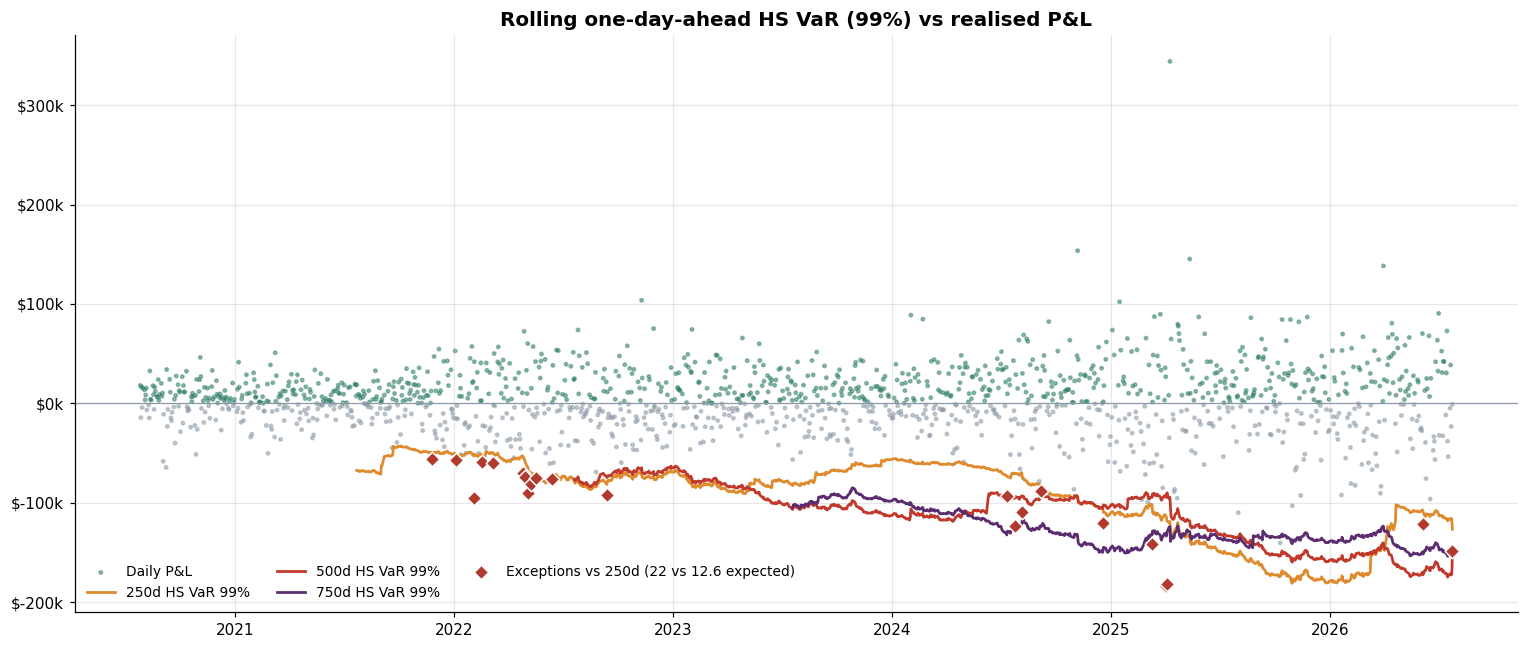

In [12]:
c = HEADLINE_CL
fig, ax = plt.subplots(figsize=(14, 6))
ax.scatter(pnl.index, pnl, s=5, c=np.where(pnl >= 0, COLORS['gain'], COLORS['muted']), alpha=0.5, label='Daily P&L')
for w in WINDOWS:
    s = -(HS[(w, c)]['VaR'] * start_value)
    ax.plot(s, color=COLORS[w], lw=1.8, label=f'{w}d HS VaR {c:.0%}')
head = HS[(HEADLINE_W, c)]['VaR'] * start_value
br = pnl[(pnl < -head) & head.notna()]
ax.scatter(br.index, br, marker='D', s=45, color=COLORS['loss'], edgecolor='white', zorder=5,
           label=f'Exceptions vs {HEADLINE_W}d ({len(br)} vs {head.notna().sum() * (1 - c):.1f} expected)')
ax.axhline(0, color=COLORS['muted'], lw=0.8); ax.yaxis.set_major_formatter(usd_fmt)
ax.set_title(f'Rolling one-day-ahead HS VaR ({c:.0%}) vs realised P&L'); ax.legend(ncol=3, fontsize=9, loc='lower left')
plt.tight_layout(); plt.show()

### 7a. Window sensitivity: model risk in one picture
If the three windows agree, the estimate is robust. When they diverge, the choice of window matters more than the data. A 250d/750d ratio above 1 means current risk is above the through-the-cycle level.

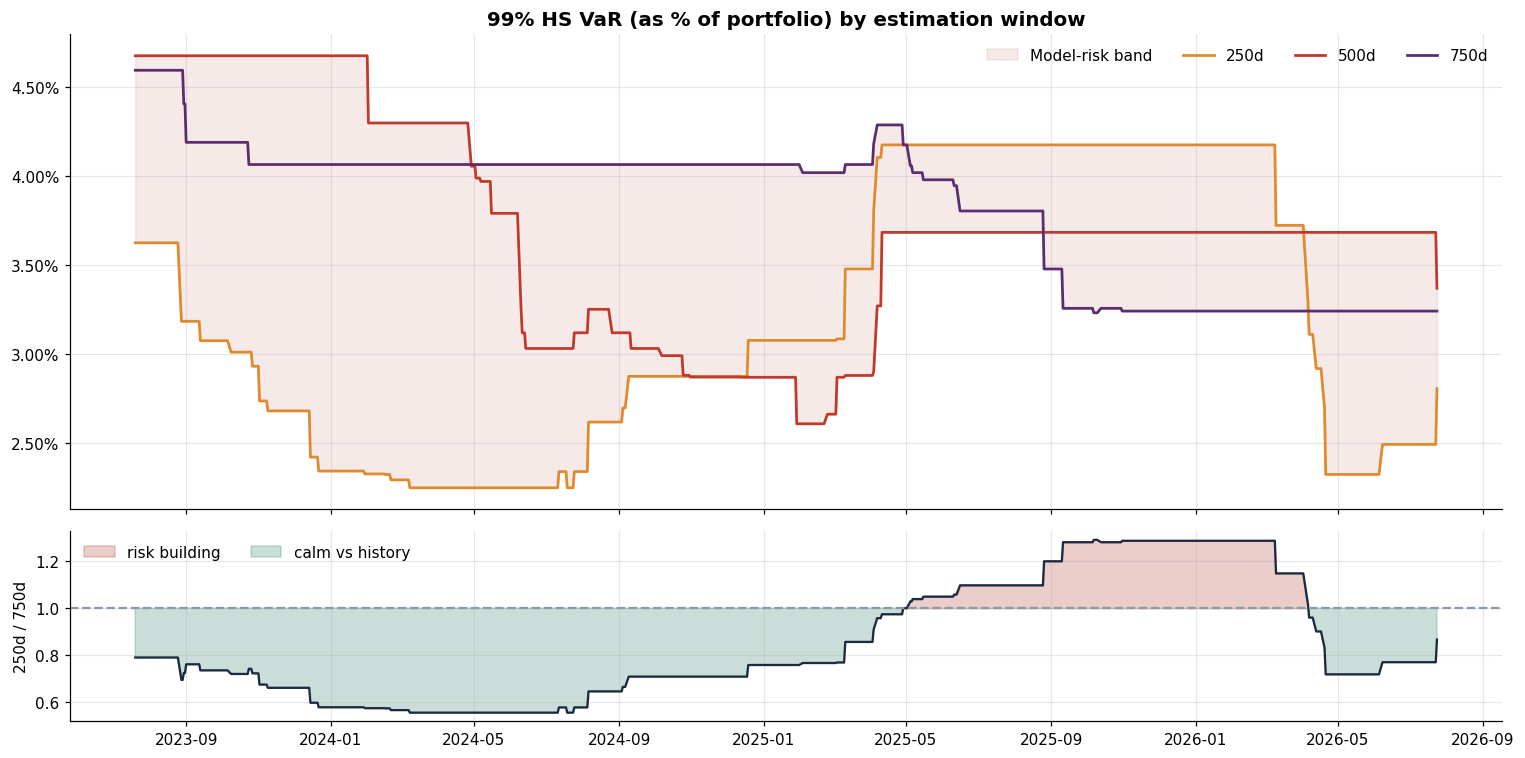

250d/750d ratio: mean 0.85, range 0.55-1.29, latest 0.87


In [13]:
c = HEADLINE_CL
band = pd.DataFrame({w: HS[(w, c)]['VaR'] for w in WINDOWS}).dropna()
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(14, 7), sharex=True, gridspec_kw={'height_ratios': [2.5, 1]})
ax.fill_between(band.index, band.min(1), band.max(1), color=COLORS['loss'], alpha=0.1, label='Model-risk band')
for w in WINDOWS: ax.plot(band[w], color=COLORS[w], lw=1.8, label=f'{w}d')
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.legend(ncol=4)
ax.set_title(f'{c:.0%} HS VaR (as % of portfolio) by estimation window')
ratio = band[250] / band[750]
ax2.plot(ratio, color=COLORS['ink']); ax2.axhline(1, color=COLORS['muted'], ls='--')
ax2.fill_between(ratio.index, 1, ratio, where=ratio >= 1, color=COLORS['loss'], alpha=0.25, label='risk building')
ax2.fill_between(ratio.index, 1, ratio, where=ratio < 1, color=COLORS['gain'], alpha=0.25, label='calm vs history')
ax2.set_ylabel('250d / 750d'); ax2.legend(ncol=2)
plt.tight_layout(); plt.show()
print(f'250d/750d ratio: mean {ratio.mean():.2f}, range {ratio.min():.2f}-{ratio.max():.2f}, latest {ratio.iloc[-1]:.2f}')

## 8. The ghost effect on a real event
We find the **largest one-day fall in HS VaR on a quiet day** (yesterday's move under 1%) and trace it back. The cause is a crash from exactly 250 trading days earlier leaving the window. VaR jumped the day *after* that crash, which is too late, and drops a year later on a day with no news. Task 5 tests whether volatility scaling helps.

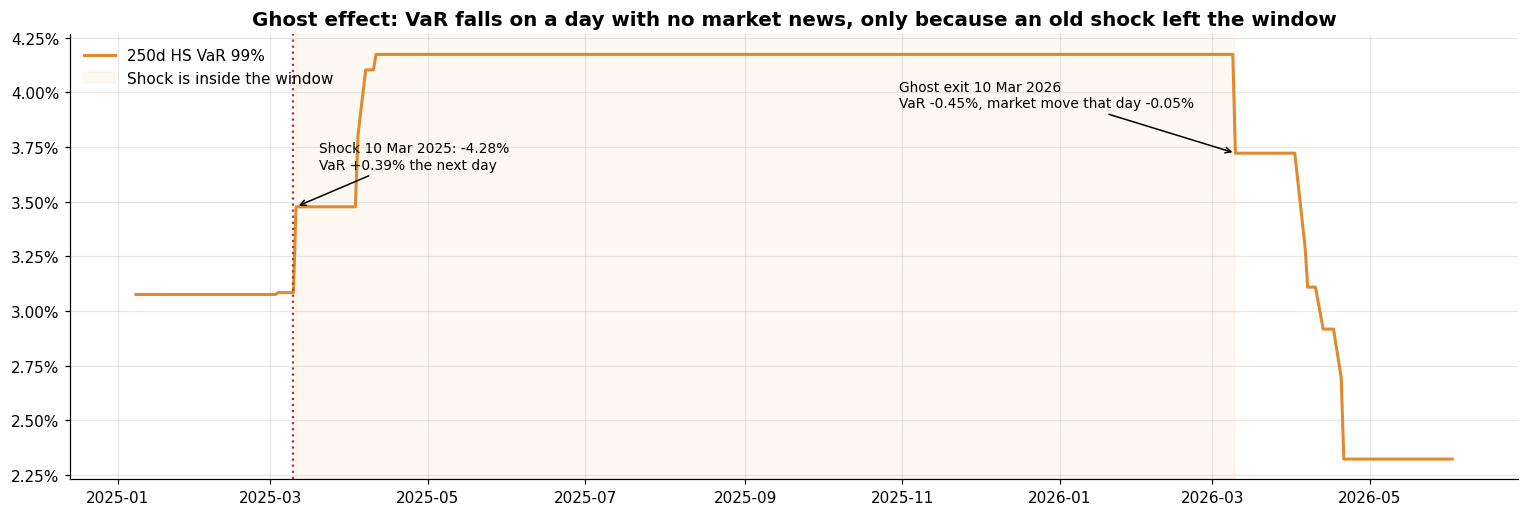

In [14]:
W, c = HEADLINE_W, HEADLINE_CL
hv = HS[(W, c)]['VaR']
quiet = returns.shift(1).abs() < 0.01                      # no big news yesterday
pos = pd.Series(np.arange(len(returns)), index=returns.index)
eligible = quiet & hv.shift(1).notna() & (pos >= 2 * W + 1)  # shock itself happened after forecasts began
t_ghost = hv.diff()[eligible].idxmin()                     # biggest quiet-day VaR fall
p = returns.index.get_loc(t_ghost) - W - 1                 # the observation that just left the window
d0, d_in, d_out = returns.index[p], returns.index[p + 1], returns.index[p + W + 1]
assert d_out == t_ghost
jump_in, jump_out = hv.iloc[p + 1] - hv.iloc[p], hv.iloc[p + W + 1] - hv.iloc[p + W]

seg = hv.iloc[max(0, p - 40):p + W + 60]
fig, ax = plt.subplots(figsize=(14, 4.8))
ax.plot(seg, color=COLORS['HS'], lw=2, label=f'{W}d HS VaR {c:.0%}')
ax.axvline(d0, color=COLORS['loss'], ls=':', lw=1.5)
ax.annotate(f'Shock {d0:%d %b %Y}: {pct(returns.iloc[p])}\nVaR {jump_in:+.2%} the next day',
            (d_in, hv.iloc[p + 1]), xytext=(15, 25), textcoords='offset points', arrowprops=dict(arrowstyle='->'), fontsize=9)
ax.annotate(f'Ghost exit {d_out:%d %b %Y}\nVaR {jump_out:+.2%}, market move that day {pct(returns.iloc[p + W + 1])}',
            (d_out, hv.iloc[p + W + 1]), xytext=(-220, 30), textcoords='offset points', arrowprops=dict(arrowstyle='->'), fontsize=9)
ax.axvspan(d_in, d_out, color=COLORS['HS'], alpha=0.06, label='Shock is inside the window')
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.legend(loc='upper left')
ax.set_title('Ghost effect: VaR falls on a day with no market news, only because an old shock left the window')
plt.tight_layout(); plt.show()

## 9. VaR vs ES, and the FRTB view
Under a Normal distribution, 97.5% ES ≈ 99% VaR (2.34σ vs 2.33σ). That equivalence is how Basel calibrated FRTB. If our 97.5% ES is clearly **above** our 99% VaR, the tail is fatter than Normal and a VaR-only view understates capital.

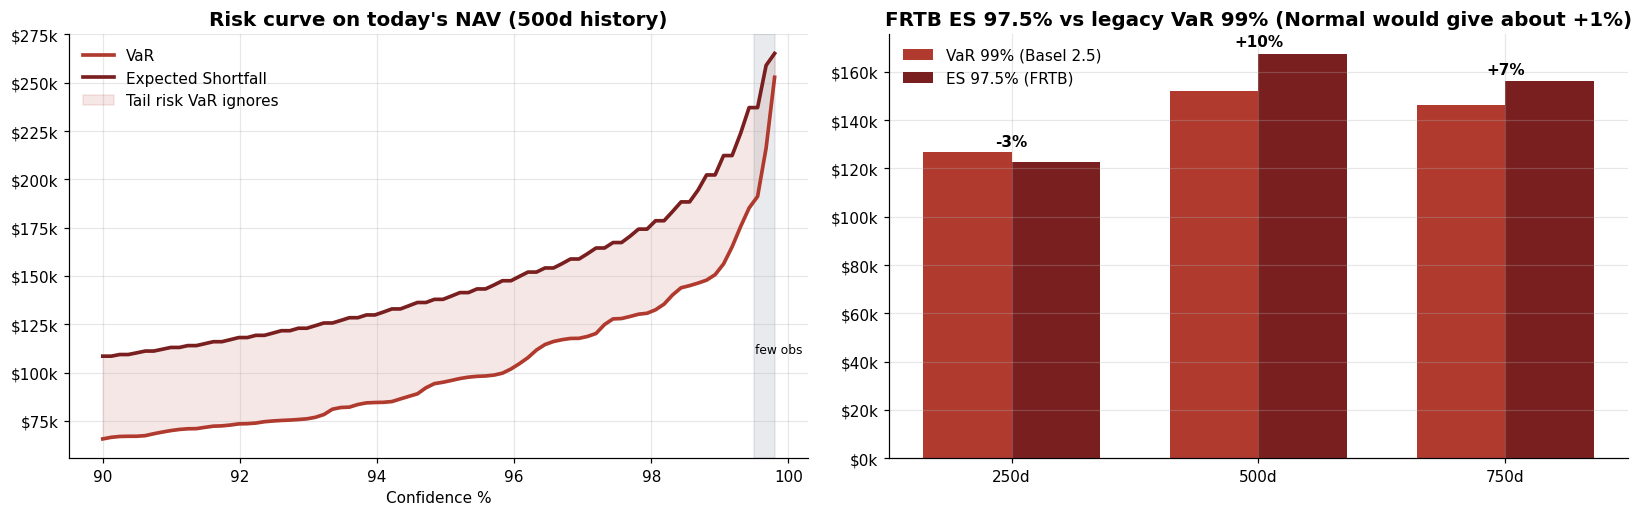

In [15]:
cs = np.linspace(0.90, 0.998, 80)
curve = np.array([var_es(returns.iloc[-500:], c) for c in cs])
fig, (a0, a1) = plt.subplots(1, 2, figsize=(15, 4.8))
a0.plot(cs * 100, curve[:, 0] * NAV, lw=2.4, color=COLORS['loss'], label='VaR')
a0.plot(cs * 100, curve[:, 1] * NAV, lw=2.4, color='#7A1F1F', label='Expected Shortfall')
a0.fill_between(cs * 100, curve[:, 0] * NAV, curve[:, 1] * NAV, color=COLORS['loss'], alpha=0.12, label='Tail risk VaR ignores')
a0.axvspan(99.5, 99.8, color=COLORS['muted'], alpha=0.2); a0.text(99.52, a0.get_ylim()[1] * 0.4, 'few obs', fontsize=8)
a0.yaxis.set_major_formatter(usd_fmt); a0.set_xlabel('Confidence %'); a0.legend()
a0.set_title('Risk curve on today\'s NAV (500d history)')

frtb = pd.DataFrame({w: {'VaR 99%': var_es(returns.iloc[-w:], 0.99)[0], 'ES 97.5%': var_es(returns.iloc[-w:], 0.975)[1]}
                     for w in WINDOWS}).T
x = np.arange(len(frtb)); a1.bar(x - 0.18, frtb['VaR 99%'] * NAV, 0.36, color=COLORS['loss'], label='VaR 99% (Basel 2.5)')
a1.bar(x + 0.18, frtb['ES 97.5%'] * NAV, 0.36, color='#7A1F1F', label='ES 97.5% (FRTB)')
for i, (v, e) in enumerate(frtb.values * NAV):
    a1.text(i, max(v, e) * 1.02, f'{e / v - 1:+.0%}', ha='center', fontweight='bold')
a1.set_xticks(x, [f'{w}d' for w in frtb.index]); a1.yaxis.set_major_formatter(usd_fmt); a1.legend()
a1.set_title('FRTB ES 97.5% vs legacy VaR 99% (Normal would give about +1%)')
plt.tight_layout(); plt.show()

## 10. Backtest preview and Basel traffic light
Exceptions are counted against the **one-day-ahead** forecasts. The **Kupiec POF** test checks whether the exception *rate* matches the stated confidence (p < 0.05 means reject). The Basel traffic light counts exceptions in the latest 250 days at 99%: green 0–4, yellow 5–9, red 10+. The zone sets the capital multiplier (3.0 to 4.0). Task 8 runs the full battery of tests, including independence and conditional coverage.

In [16]:
bt = backtest_table('HS', HS)
style_bt(bt)

Model,Window,Confidence,Start,Days,Exceptions,Expected,Rate,Kupiec p,Kupiec,Last 250d exc.,Basel zone,Avg VaR %,Avg ES %,VaR churn %
HS,250,95.0%,2021-07-23,1256,70,62.8,5.57%,0.360,PASS,8,-,2.26%,3.09%,0.007%
HS,250,99.0%,2021-07-23,1256,22,12.6,1.75%,0.016,REJECT,2,GREEN,3.53%,4.12%,0.009%
HS,250,99.5%,2021-07-23,1256,16,6.3,1.27%,0.001,REJECT,1,-,4.01%,4.37%,0.011%
HS,500,95.0%,2022-07-21,1006,47,50.3,4.67%,0.629,PASS,11,-,2.32%,3.29%,0.003%
HS,500,99.0%,2022-07-21,1006,10,10.1,0.99%,0.985,PASS,0,GREEN,3.95%,4.67%,0.004%
HS,500,99.5%,2022-07-21,1006,6,5.0,0.60%,0.674,PASS,0,-,4.37%,4.97%,0.004%
HS,750,95.0%,2023-07-20,756,28,37.8,3.70%,0.087,PASS,12,-,2.33%,3.24%,0.003%
HS,750,99.0%,2023-07-20,756,4,7.6,0.53%,0.153,PASS,1,GREEN,3.83%,4.67%,0.003%
HS,750,99.5%,2023-07-20,756,2,3.8,0.26%,0.313,PASS,0,-,4.56%,5.15%,0.002%


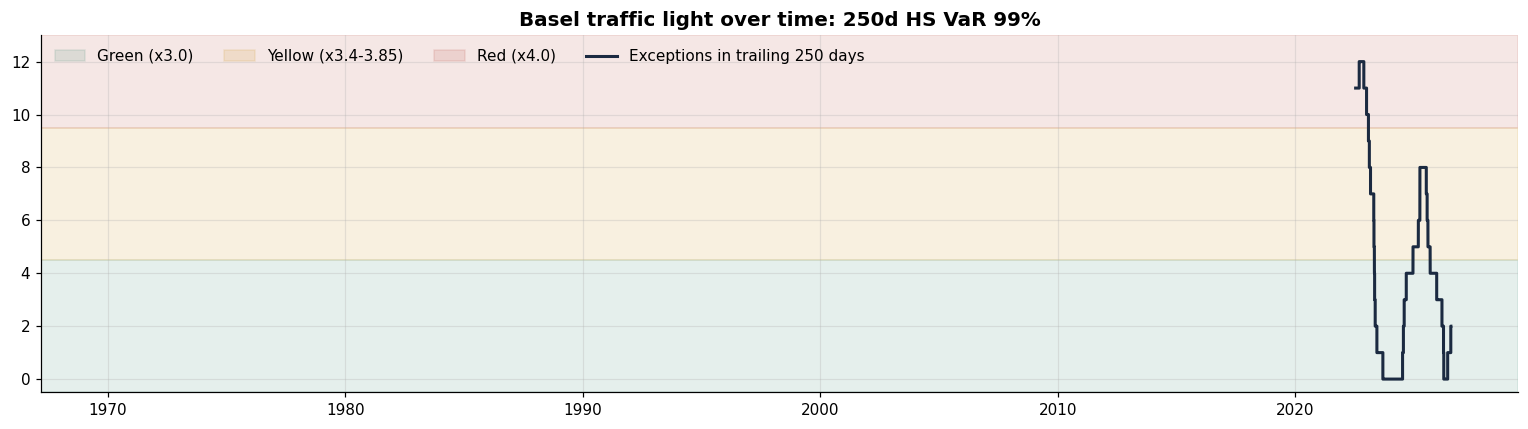

Current zone: GREEN (2 exceptions) -> capital multiplier 3.0
Time spent in each zone: GREEN 63%, YELLOW 24%, RED 14%


In [17]:
hit = (returns < -HS[(HEADLINE_W, HEADLINE_CL)]['VaR']).astype(float).where(HS[(HEADLINE_W, HEADLINE_CL)]['VaR'].notna())
count = hit.rolling(250, min_periods=250).sum().dropna()
fig, ax = plt.subplots(figsize=(14, 4))
ax.axhspan(-0.5, 4.5, color='#2E7D68', alpha=0.12, label='Green (x3.0)')
ax.axhspan(4.5, 9.5, color='#C78B00', alpha=0.12, label='Yellow (x3.4-3.85)')
ax.axhspan(9.5, max(12, count.max() + 1), color='#B03A2E', alpha=0.12, label='Red (x4.0)')
ax.step(count.index, count, where='post', color=COLORS['ink'], lw=2, label='Exceptions in trailing 250 days')
ax.set_ylim(-0.5, max(12, count.max() + 1)); ax.legend(ncol=4, loc='upper left')
ax.set_title(f'Basel traffic light over time: {HEADLINE_W}d HS VaR {HEADLINE_CL:.0%}')
plt.tight_layout(); plt.show()
x_now = int(count.iloc[-1])
print(f'Current zone: {basel_zone(x_now)} ({x_now} exceptions) -> capital multiplier {BASEL_MULT.get(x_now, 4.0)}')
print(f'Time spent in each zone: ' + ', '.join(f'{z} {v:.0%}' for z, v in count.map(basel_zone).value_counts(normalize=True).items()))

## 11. Export for Tasks 5–9

In [18]:
hs_out = export_model('HS', HS, 'HS_VaR.csv')
update_summary(bt, NEXT)
hs_out.filter(like='_250d_99').dropna().tail(3)

Saved HS_VaR.csv (1,506 rows x 48 cols) + data dictionary
VaR_Model_Summary.csv now holds models: ['EWMA', 'GARCH', 'HS']


,HS_VaR_250d_99_Ret,HS_ES_250d_99_Ret,HS_VaR_250d_99,HS_ES_250d_99,HS_Breach_250d_99,HS_VaR_250d_99p5_Ret,HS_ES_250d_99p5_Ret,HS_VaR_250d_99p5,HS_ES_250d_99p5,HS_Breach_250d_99p5
Date,,,,,,,,,,
2026-07-22,0.0249,0.0299,"116,909.9555","140,276.2995",0.0000,0.0290,0.0318,"136,210.8655","149,356.2881",0.0000
2026-07-23,0.0249,0.0299,"116,330.4553","139,580.9768",1.0000,0.0290,0.0318,"135,535.6944","148,615.9577",1.0000
2026-07-24,0.0281,0.0318,"126,825.6124","143,784.1416",0.0000,0.0313,0.0327,"141,617.9432","147,856.8565",0.0000


## 12. Executive summary (generated from the numbers above)

In [19]:
h = bt[(bt.Window == HEADLINE_W) & (bt.Confidence == HEADLINE_CL)].iloc[0]
v, e = NEXT[(HEADLINE_W, HEADLINE_CL)]
v750 = NEXT[(750, HEADLINE_CL)][0]
n_pass = (bt['Kupiec'] == 'PASS').sum()
display(Markdown(f"""
**Headline ({HEADLINE_CL:.0%}, {HEADLINE_W}-day HS, NAV {money(NAV)})**
- Next-day **VaR {pct(v)} = {money(v * NAV)}**: on about 99 days in 100, the loss should stay below this.
- Next-day **ES {pct(e)} = {money(e * NAV)}**: the average loss on the days that do break it. ES/VaR = **{e / v:.2f}** (Normal ≈ {norm_ratio(HEADLINE_CL):.2f}).
- The 750-day window gives VaR {pct(v750)}, so recent risk is **{'above' if v > v750 else 'below'}** the three-year level.

**Validation.** {h.Exceptions} exceptions against {h.Expected:.1f} expected over {h.Days:,} forecast days (Kupiec p = {h['Kupiec p']:.3f}, **{h.Kupiec}**).
Current Basel zone: **{h['Basel zone']}**. {n_pass} of {len(bt)} window/confidence combinations pass Kupiec.

**What this means.** Returns are fat-tailed (excess kurtosis {returns.kurt():.1f}), so a non-parametric model is the right starting point.
But HS reacts late and shows the ghost effect, because every day in the window gets equal weight. **Task 5** tests whether EWMA volatility scaling fixes this,
and its results drop straight into the same comparison through `VaR_Model_Summary.csv`.
"""))


**Headline (99%, 250-day HS, NAV $4,520,228)**
- Next-day **VaR 2.81% = $126,797**: on about 99 days in 100, the loss should stay below this.
- Next-day **ES 3.18% = $143,752**: the average loss on the days that do break it. ES/VaR = **1.13** (Normal ≈ 1.15).
- The 750-day window gives VaR 3.24%, so recent risk is **below** the three-year level.

**Validation.** 22 exceptions against 12.6 expected over 1,256 forecast days (Kupiec p = 0.016, **REJECT**).
Current Basel zone: **GREEN**. 7 of 9 window/confidence combinations pass Kupiec.

**What this means.** Returns are fat-tailed (excess kurtosis 4.4), so a non-parametric model is the right starting point.
But HS reacts late and shows the ghost effect, because every day in the window gets equal weight. **Task 5** tests whether EWMA volatility scaling fixes this,
and its results drop straight into the same comparison through `VaR_Model_Summary.csv`.


---
*Task 4 complete. Next: **Task 5, EWMA volatility-scaled (filtered) Historical Simulation.***

*Prepared by Arham Shah.*